# Наиболее точная модель раннего прогноза: расширенные признаки, подбор настроек и ансамбль

**Автор:** Улханов А.К., AITU, 7M06105 · **Данные:** OULAD · **Прогноз:** на 10-й неделе курса (день 70)

Это продолжение ноутбука `OULAD_LSTM_model.ipynb`. Там LSTM на 6 недельных показателях дала
ROC-AUC 0.856. Здесь ищем **максимальную точность**:

1. **Расширенные признаки (+53):** клики по 20 типам учебных материалов, тренды активности,
   перерывы, баллы по каждому заданию, активность относительно однокурсников, курс.
2. **Сильные классические модели:** LightGBM и XGBoost с гиперпараметрами, подобранными Optuna
   (100 и 60 попыток).
3. **Лучшая нейросеть** из шести архитектур (LSTM, GRU, BiLSTM, LSTM + attention, CNN, Transformer),
   подобранная Optuna (60 попыток): **BiLSTM** на недельной последовательности + все табличные признаки.
4. **Ансамбль:** взвешенное среднее LightGBM, XGBoost и BiLSTM; веса выбираются на валидации.

Правило честной оценки: гиперпараметры, веса ансамбля и порог классификации выбираются **только на
валидации**; тестовая выборка используется один раз.

> **Перед запуском** (один раз): `pip install pandas numpy scikit-learn matplotlib scipy ipykernel lightgbm xgboost`
> и `pip install torch --index-url https://download.pytorch.org/whl/cpu`.
> Время прогона ~10–20 минут (5 BiLSTM). Для быстрой проверки поставьте `N_SEEDS = 1`.

In [1]:
# ── Настройки эксперимента ─────────────────────────────────────────────────
from pathlib import Path

DATA_DIR = Path("../data")   # папка с CSV-файлами OULAD (укажите свою)
CUTOFF_DAY = 70        # день прогноза: используем данные только до 70-го дня (≈ 10-я неделя)
SEED = 42              # фиксируем случайность, чтобы результат повторялся
N_SEEDS = 5            # сколько раз обучать каждую модель с разной случайностью (ответы усредняются)

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
KEY = ["code_module", "code_presentation", "id_student"]   # одна запись = студент на курсе
print("PyTorch", torch.__version__)
import copy
import lightgbm as lgb
import xgboost as xgb
torch.set_num_threads(2)

PyTorch 2.15.0+cu132


## 1. Загрузка данных

OULAD — открытый датасет Open University (Великобритания): 22 курса, 32 593 записи студентов на курсы.
Берём пять таблиц:

| Таблица | Что в ней |
|---|---|
| `studentInfo` | демография и итоговый результат (Pass / Distinction / Fail / Withdrawn) |
| `studentRegistration` | дата регистрации и отчисления |
| `assessments` | задания курса: тип, дедлайн, вес |
| `studentAssessment` | когда студент сдал задание и какой балл получил |
| `studentVle` | клики в LMS по дням — **10,6 млн строк** |

In [3]:
def read(name):
    # В OULAD пропуски обозначены знаком "?"
    return pd.read_csv(DATA_DIR / f"{name}.csv", na_values=["?", ""], low_memory=False)

info = read("studentInfo")
reg = read("studentRegistration")
assessments = read("assessments")
student_ass = read("studentAssessment")
vle = read("studentVle")

for name, df in [("studentInfo", info), ("studentRegistration", reg), ("assessments", assessments),
                 ("studentAssessment", student_ass), ("studentVle", vle)]:
    print(f"{name:20s} {len(df):>12,} строк")

studentInfo                32,593 строк
studentRegistration        32,593 строк
assessments                   206 строк
studentAssessment         173,912 строк
studentVle             10,655,280 строк


## 2. Целевая переменная: кто в зоне риска

* `at_risk = 1` — студент провалил курс (**Fail**) или бросил его (**Withdrawn**);
* `at_risk = 0` — сдал (**Pass** или **Distinction**).

Прогноз делается на **70-й день**. Студенты, которые уже бросили курс к этому дню, исключаются:
их исход уже известен, предсказывать его нет смысла.

In [4]:
info = info.drop_duplicates(KEY)
info["at_risk"] = info["final_result"].isin(["Fail", "Withdrawn"]).astype(int)

info = info.merge(reg[KEY + ["date_registration", "date_unregistration"]], on=KEY, how="left")
still_enrolled = info["date_unregistration"].isna() | (info["date_unregistration"] > CUTOFF_DAY)
students = info[still_enrolled].drop(columns="date_unregistration").reset_index(drop=True)

print(f"Всего записей: {len(info):,}; ещё учатся на день {CUTOFF_DAY}: {len(students):,}")
print(f"Доля студентов в зоне риска: {students['at_risk'].mean():.1%}")
students["final_result"].value_counts()

Всего записей: 32,593; ещё учатся на день 70: 26,069
Доля студентов в зоне риска: 41.0%


final_result
Pass           12361
Fail            7044
Withdrawn       3640
Distinction     3024
Name: count, dtype: int64

### Демографические признаки

Категории с естественным порядком (образование, возраст, индекс бедности района `imd_band`) кодируем
числами по порядку. В `imd_band` есть известная опечатка `"10-20"` без `%`, исправляем её.

In [5]:
EDUCATION = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2,
             "HE Qualification": 3, "Post Graduate Qualification": 4}
AGE = {"0-35": 0, "35-55": 1, "55<=": 2}
IMD = {f"{10*i}-{10*(i+1)}%": i for i in range(10)}

imd = students["imd_band"].replace({"10-20": "10-20%"})
students["imd_missing"] = imd.isna().astype(int)
students["imd_band"] = imd.map(IMD)
students["highest_education"] = students["highest_education"].map(EDUCATION)
students["age_band"] = students["age_band"].map(AGE)
students["gender_m"] = (students["gender"] == "M").astype(int)
students["disability_y"] = (students["disability"] == "Y").astype(int)
students = students.drop(columns=["gender", "disability"])

DEMOGRAPHIC = ["gender_m", "disability_y", "highest_education", "age_band", "imd_band",
               "imd_missing", "num_of_prev_attempts", "studied_credits"]
students[KEY + DEMOGRAPHIC + ["date_registration", "at_risk"]].head()

,code_module,code_presentation,id_student,gender_m,disability_y,highest_education,age_band,imd_band,imd_missing,num_of_prev_attempts,studied_credits,date_registration,at_risk
0,AAA,2013J,11391,1,0,3,2,9.0,0,0,240,-159.0,0
1,AAA,2013J,28400,0,0,3,1,2.0,0,0,60,-53.0,0
2,AAA,2013J,31604,0,0,2,1,5.0,0,0,60,-52.0,0
3,AAA,2013J,32885,0,0,1,0,5.0,0,0,60,-176.0,0
4,AAA,2013J,38053,1,0,2,1,8.0,0,0,60,-110.0,0


## 3. Признаки для классических моделей

Классические модели видят студента как **одну строку итогов** на 70-й день:

* **LMS:** всего кликов, активных дней, кликов за активный день, клики до начала курса, клики за каждую неделю;
* **задания:** доля сданных, средний и взвешенный балл, число опозданий, на сколько дней раньше дедлайна сдаёт.

Важно: используются **только события до дня прогноза**, иначе модель «подсмотрит в будущее».

In [6]:
N_WEEKS = (CUTOFF_DAY + 1) // 7    # полные недели до дня прогноза: 0..9 → 10 недель

# ---- LMS
v = vle[vle["date"] <= CUTOFF_DAY]
g = v.groupby(KEY)
vle_feat = pd.DataFrame({
    "total_clicks": g["sum_click"].sum(),
    "active_days": g["date"].nunique(),
    "clicks_pre": v[v["date"] < 0].groupby(KEY)["sum_click"].sum(),   # активность до старта курса
})
vle_feat["clicks_pre"] = vle_feat["clicks_pre"].fillna(0)
vle_feat["clicks_per_active_day"] = vle_feat["total_clicks"] / vle_feat["active_days"]
started = v[v["date"] >= 0].assign(week=lambda d: d["date"] // 7)
weekly = (started.pivot_table(index=KEY, columns="week", values="sum_click", aggfunc="sum")
          .reindex(columns=range(N_WEEKS)).fillna(0))
weekly.columns = [f"clicks_w{w}" for w in range(N_WEEKS)]
vle_feat = vle_feat.join(weekly).reset_index()

# ---- задания (без итогового экзамена, только с дедлайном до дня прогноза)
due = assessments[(assessments["assessment_type"] != "Exam") & (assessments["date"] <= CUTOFF_DAY)]
n_due = due.groupby(["code_module", "code_presentation"]).size().rename("n_due").reset_index()
subs = student_ass[student_ass["date_submitted"] <= CUTOFF_DAY].merge(due, on="id_assessment")
subs = subs.assign(is_late=(subs["date_submitted"] > subs["date"]).astype(int),
                   days_early=subs["date"] - subs["date_submitted"],
                   score_x_weight=subs["score"] * subs["weight"])
g = subs.groupby(KEY)
ass_feat = pd.DataFrame({"n_submitted": g.size(), "mean_score": g["score"].mean(),
                         "n_late": g["is_late"].sum(), "mean_days_early": g["days_early"].mean(),
                         "_sw": g["score_x_weight"].sum(), "_w": g["weight"].sum()})
ass_feat["weighted_score"] = np.where(ass_feat["_w"] > 0,
                                      ass_feat["_sw"] / ass_feat["_w"].replace(0, np.nan),
                                      ass_feat["mean_score"])
ass_feat = ass_feat.drop(columns=["_sw", "_w"]).reset_index()

# ---- собираем одну таблицу
table = (students.merge(vle_feat, on=KEY, how="left").merge(ass_feat, on=KEY, how="left")
         .merge(n_due, on=["code_module", "code_presentation"], how="left"))
counts = [c for c in table if c.startswith("clicks_w")] + [
    "total_clicks", "active_days", "clicks_per_active_day", "clicks_pre", "n_submitted", "n_late", "n_due"]
table[counts] = table[counts].fillna(0)
table["submission_rate"] = (table["n_submitted"] / table["n_due"].where(table["n_due"] > 0)).fillna(0)
table["late_rate"] = (table["n_late"] / table["n_submitted"].where(table["n_submitted"] > 0)).fillna(0)
table["no_submissions"] = (table["n_submitted"] == 0).astype(int)
table[["mean_score", "weighted_score", "mean_days_early"]] = (
    table[["mean_score", "weighted_score", "mean_days_early"]].fillna(0))

# всё, кроме идентификаторов, региона и ответа (date_registration — за сколько дней до старта записался)
FEATURES = [c for c in table.columns if c not in set(KEY) | {"region", "final_result", "at_risk"}]
FEATURES.remove("date_registration")                      # тот же порядок столбцов, что в проекте
FEATURES.insert(FEATURES.index("disability_y") + 1, "date_registration")
print(f"Признаков для классических моделей: {len(FEATURES)}")
table[FEATURES].describe().T[["mean", "50%", "max"]].head(12)

Признаков для классических моделей: 32


,mean,50%,max
highest_education,1.767,2.0,4.0
imd_band,4.313,4.0,9.0
age_band,0.312,0.0,2.0
num_of_prev_attempts,0.159,0.0,6.0
studied_credits,75.593,60.0,630.0
imd_missing,0.038,0.0,1.0
gender_m,0.548,1.0,1.0
disability_y,0.093,0.0,1.0
date_registration,-65.905,-53.0,167.0
total_clicks,637.536,404.0,11964.0


### Как отличается активность успешных студентов и студентов в зоне риска

Уже по графику видно, что студенты в зоне риска с первых недель заходят в LMS реже.
LSTM должна уловить не только уровень, но и **динамику**: например, постепенное снижение активности.

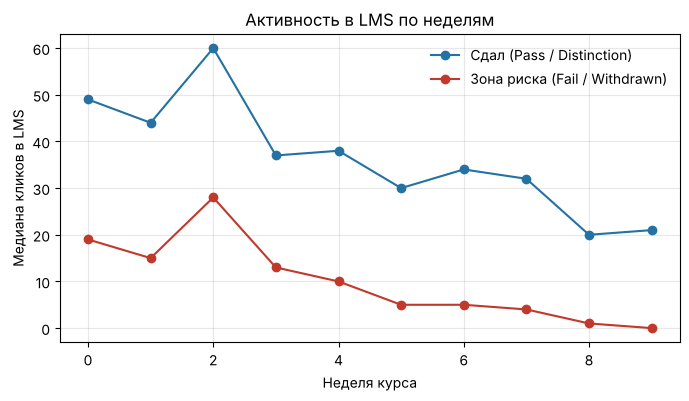

In [7]:
week_cols = [f"clicks_w{w}" for w in range(N_WEEKS)]
med = table.groupby("at_risk")[week_cols].median()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(N_WEEKS), med.loc[0], marker="o", color="#2471a3", label="Сдал (Pass / Distinction)")
ax.plot(range(N_WEEKS), med.loc[1], marker="o", color="#c0392b", label="Зона риска (Fail / Withdrawn)")
ax.set_xlabel("Неделя курса"); ax.set_ylabel("Медиана кликов в LMS")
ax.set_title("Активность в LMS по неделям"); ax.grid(alpha=.3); ax.legend(frameon=False)
plt.show()

## 4. Недельные последовательности: неделя за неделей

В этом главное отличие от классических моделей. Каждый студент — это таблица **10 недель × 6 чисел**
из двух источников данных:

| № | Признак | Источник |
|---|---|---|
| 1 | `log_clicks` — log(1 + клики за неделю) | LMS |
| 2 | `active_days` — дней с хотя бы одним кликом (0–7) | LMS |
| 3 | `n_due` — сколько дедлайнов на этой неделе | задания |
| 4 | `n_submitted` — сколько работ студент сдал | задания |
| 5 | `mean_score` — средний балл за эти работы / 100 | задания |
| 6 | `n_late` — сколько из них сдано с опозданием | задания |

In [8]:
CHANNELS = ["log_clicks", "active_days", "n_due", "n_submitted", "mean_score", "n_late"]
seq = np.zeros((len(table), N_WEEKS, len(CHANNELS)), dtype=np.float32)
rows = table[KEY].assign(_row=np.arange(len(table)))

def put(frame, channel, values):
    seq[frame["_row"].to_numpy(), frame["week"].to_numpy(), CHANNELS.index(channel)] = values.to_numpy()

def week_of(day):   # дни до старта → неделя 0, неполная последняя неделя → последняя полная
    return (day // 7).clip(0, N_WEEKS - 1).astype(int)

# источник 1: LMS (только полные недели)
v = vle[(vle["date"] >= 0) & (vle["date"] < N_WEEKS * 7)].assign(week=lambda d: d["date"] // 7)
w = (v.groupby(KEY + ["week"]).agg(clicks=("sum_click", "sum"), days=("date", "nunique"))
     .reset_index().merge(rows, on=KEY))
put(w, "log_clicks", np.log1p(w["clicks"]))
put(w, "active_days", w["days"])

# источник 2: задания
d = due.assign(week=week_of(due["date"]))
nd = (d.groupby(["code_module", "code_presentation", "week"]).size().rename("n").reset_index()
      .merge(rows, on=["code_module", "code_presentation"]))
put(nd, "n_due", nd["n"])
s = student_ass[student_ass["date_submitted"] <= CUTOFF_DAY].merge(due, on="id_assessment")
s = s.assign(week=week_of(s["date_submitted"]), late=(s["date_submitted"] > s["date"]).astype(int))
pw = (s.groupby(KEY + ["week"]).agg(n=("id_assessment", "size"), score=("score", "mean"),
                                    late=("late", "sum")).reset_index().merge(rows, on=KEY))
put(pw, "n_submitted", pw["n"])
put(pw, "mean_score", pw["score"].fillna(0) / 100)
put(pw, "n_late", pw["late"])

STATIC = DEMOGRAPHIC + ["clicks_pre"]          # то, что не меняется по неделям
static = table[STATIC].to_numpy(dtype=float)
y = table["at_risk"].to_numpy()
print("Форма последовательностей:", seq.shape, "→ (студенты, недели, признаки)")
pd.DataFrame(seq[0], columns=CHANNELS, index=[f"неделя {i}" for i in range(N_WEEKS)]).round(2)

Форма последовательностей: (26069, 10, 6) → (студенты, недели, признаки)


,log_clicks,active_days,n_due,n_submitted,mean_score,n_late
неделя 0,5.21,4.0,0.0,0.0,0.00,0.0
неделя 1,3.04,1.0,0.0,0.0,0.00,0.0
неделя 2,4.62,2.0,1.0,1.0,0.78,0.0
неделя 3,0.00,0.0,0.0,0.0,0.00,0.0
неделя 4,3.30,3.0,0.0,0.0,0.00,0.0
неделя 5,4.11,2.0,0.0,0.0,0.00,0.0
неделя 6,3.14,2.0,0.0,0.0,0.00,0.0
неделя 7,3.04,3.0,1.0,1.0,0.85,0.0
неделя 8,0.00,0.0,0.0,0.0,0.00,0.0
неделя 9,2.83,1.0,0.0,0.0,0.00,0.0


## 5. Разбиение на обучение, проверку и тест: 70 / 15 / 15

* **70 % — обучение:** на этих студентах модель учится;
* **15 % — валидация:** по ней решаем, когда остановить обучение LSTM;
* **15 % — тест:** финальный «экзамен» на студентах, которых модель ни разу не видела.

Один студент может учиться на нескольких курсах, поэтому делим **по студентам** (`GroupShuffleSplit`):
один человек никогда не попадает в две части. Иначе модель «узнала» бы его на тесте, и это утечка данных.

In [9]:
groups = table["id_student"]
outer = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
train_idx, rest_idx = next(outer.split(table, groups=groups))
inner = GroupShuffleSplit(n_splits=1, train_size=0.15 / (1 - 0.70), random_state=SEED)
val_pos, test_pos = next(inner.split(rest_idx, groups=groups.iloc[rest_idx]))
val_idx, test_idx = rest_idx[val_pos], rest_idx[test_pos]

ids = [set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx)]
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), "студент в двух частях!"
for name, idx in [("обучение", train_idx), ("валидация", val_idx), ("тест", test_idx)]:
    print(f"{name:10s} {len(idx):>6,} записей, в зоне риска {y[idx].mean():.1%}")

обучение   18,248 записей, в зоне риска 41.3%
валидация   3,902 записей, в зоне риска 41.9%
тест        3,919 записей, в зоне риска 38.6%


## 6. Расширенные признаки (+53)

| Группа | Признаки | Зачем |
|---|---|---|
| Типы материалов | клики отдельно по 20 типам: `resource`, `oucontent`, `quiz`, `forumng`, `subpage`, … | «смотрит лекции, но не решает тесты» ≠ «активен на форуме» |
| Тренды | наклон недельной активности, последние 3 недели против первых 3, неактивные недели | падение активности — ранний сигнал |
| Перерывы | самый долгий перерыв (дни), дней с последнего захода, активных дней за 2 недели | «пропал» сейчас важнее, чем в начале |
| Задания | балл и задержка по каждому из первых 4 заданий, тренд баллов, средний TMA и CMA | динамика успеваемости |
| Относительно группы | клики, дни, баллы, доля сданных — в сигмах от среднего по курсу; ранг по кликам | 300 кликов на одном курсе — много, на другом — мало |
| Курс | модуль (AAA–GGG), семестр B/J, год, длина курса | курсы сильно различаются по сложности |

Все признаки считаются только по событиям **до 70-го дня**.

In [10]:
PRES = ["code_module", "code_presentation"]
BASE_FEATURES = list(FEATURES)

# ---- клики по типам материалов
sites = read("vle")[["id_site", "activity_type"]]
v = vle[vle["date"] <= CUTOFF_DAY].merge(sites, on="id_site", how="left")
v["activity_type"] = v["activity_type"].fillna("other")
TYPES = sorted(v["activity_type"].unique())
by_type = v.pivot_table(index=KEY, columns="activity_type", values="sum_click", aggfunc="sum", fill_value=0)
by_type.columns = [f"clk_{t}" for t in by_type.columns]
by_type = by_type.join(v.groupby(KEY)["id_site"].nunique().rename("n_distinct_sites")).reset_index()
tab = table.merge(by_type, on=KEY, how="left")
type_cols = [f"clk_{t}" for t in TYPES] + ["n_distinct_sites"]
tab[type_cols] = tab[type_cols].fillna(0)

# ---- тренды и перерывы
row_of = tab[KEY].assign(_row=np.arange(len(tab)))
week_clicks = tab[[f"clicks_w{w}" for w in range(N_WEEKS)]].to_numpy()
logw = np.log1p(week_clicks)
wk = np.arange(N_WEEKS)
tab["click_slope"] = ((logw - logw.mean(1, keepdims=True)) * (wk - wk.mean())).sum(1) / ((wk - wk.mean()) ** 2).sum()
tab["last3_vs_first3"] = np.log1p(week_clicks[:, -3:].sum(1)) - np.log1p(week_clicks[:, :3].sum(1))
tab["weeks_inactive"] = (week_clicks == 0).sum(1)

vd = v[(v["date"] >= 0)].merge(row_of, on=KEY)
daily = np.zeros((len(tab), CUTOFF_DAY + 1), dtype=bool)
daily[vd["_row"], vd["date"]] = True

def longest_gap(a):
    best = cur = 0
    for x in a:
        cur = 0 if x else cur + 1
        best = max(best, cur)
    return best

tab["longest_gap_days"] = [longest_gap(r) for r in daily]
tab["days_since_last_active"] = [int(np.argmax(r[::-1])) if r.any() else len(r) for r in daily]
tab["active_days_last14"] = daily[:, -14:].sum(1)

# ---- задания по отдельности
due_sorted = due.sort_values(PRES + ["date", "id_assessment"]).copy()
due_sorted["order"] = due_sorted.groupby(PRES).cumcount()
sb = student_ass[student_ass["date_submitted"] <= CUTOFF_DAY].merge(due_sorted, on="id_assessment").merge(row_of, on=KEY)
for j in range(4):
    sj = sb[sb["order"] == j]
    sc, dl = np.full(len(tab), np.nan), np.full(len(tab), np.nan)
    sc[sj["_row"]] = sj["score"]; dl[sj["_row"]] = sj["date_submitted"] - sj["date"]
    tab[f"score_a{j+1}"], tab[f"delay_a{j+1}"] = sc, dl
g = sb.sort_values("date").groupby("_row")["score"]
trend = np.full(len(tab), np.nan); d_ = g.last() - g.first(); trend[d_.index] = d_.values
tab["score_trend"] = trend
by_kind = sb.pivot_table(index="_row", columns="assessment_type", values="score", aggfunc="mean")
for kind, col in (("TMA", "tma_mean"), ("CMA", "cma_mean")):
    arr = np.full(len(tab), np.nan)
    if kind in by_kind:
        arr[by_kind.index] = by_kind[kind].values
    tab[col] = arr

# ---- относительно однокурсников
for c in ["total_clicks", "active_days", "mean_score", "weighted_score", "submission_rate"]:
    grp = tab.groupby(PRES)[c]
    tab[f"rel_{c}"] = (tab[c] - grp.transform("mean")) / (grp.transform("std") + 1e-9)
tab["rel_rank_clicks"] = tab.groupby(PRES)["total_clicks"].rank(pct=True)

# ---- курс
for m in sorted(tab["code_module"].unique()):
    tab[f"mod_{m}"] = (tab["code_module"] == m).astype(int)
tab["pres_B"] = tab["code_presentation"].str.endswith("B").astype(int)
tab["pres_2014"] = tab["code_presentation"].str.startswith("2014").astype(int)
tab = tab.merge(read("courses"), on=PRES, how="left")

ENRICHED = [c for c in tab.columns if c not in BASE_FEATURES and c not in set(KEY) | {"region", "final_result", "at_risk"}]
ALL_FEATURES = BASE_FEATURES + ENRICHED
X_all = tab[ALL_FEATURES].astype(float).to_numpy()
print(f"Признаков: базовых {len(BASE_FEATURES)} + новых {len(ENRICHED)} = {len(ALL_FEATURES)}")

Признаков: базовых 32 + новых 53 = 85


## 7. Опорные модели из первого ноутбука

Чтобы измерить улучшение, на том же разбиении обучаем прежние лучшие модели: Random Forest на 32
базовых признаках и LSTM на 6 недельных показателях + демографии.

In [11]:
def to_tensor(a):
    return torch.from_numpy(np.asarray(a, dtype=np.float32))

class Scaler:
    # стандартизация по обучающей части; пропуски → медиана
    def __init__(self, seq_tr, st_tr):
        f = seq_tr.reshape(-1, seq_tr.shape[-1]); self.sm, self.ss = f.mean(0), f.std(0) + 1e-6
        med = np.nanmedian(st_tr, axis=0); self.med = np.where(np.isnan(med), 0, med)
        filled = np.where(np.isnan(st_tr), self.med, st_tr); self.xm, self.xs = filled.mean(0), filled.std(0) + 1e-6
    def __call__(self, s, x):
        return to_tensor((s - self.sm) / self.ss), to_tensor((np.where(np.isnan(x), self.med, x) - self.xm) / self.xs)

def predict_net(net, s, x):
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net(s, x)).numpy()

def evaluate(y_true, y_pred, y_score):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_score)}

# --- Random Forest на базовых признаках
X = table[FEATURES]
rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                          n_jobs=-1, random_state=SEED))
rf.fit(X.iloc[train_idx], y[train_idx])
val_score = {"Random Forest (базовые признаки)": rf.predict_proba(X.iloc[val_idx])[:, 1]}
test_score = {"Random Forest (базовые признаки)": rf.predict_proba(X.iloc[test_idx])[:, 1]}

# --- прежняя LSTM (32 нейрона, 6 показателей + демография), как в первом ноутбуке
class TemporalRiskNet(nn.Module):
    def __init__(self, n_ch, n_st, hidden=32, static_hidden=16, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_ch, hidden, batch_first=True)
        self.static = nn.Sequential(nn.Linear(n_st, static_hidden), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden + static_hidden, 16), nn.ReLU(), nn.Linear(16, 1))
    def forward(self, s, x):
        _, (h, _) = self.lstm(s)
        return self.head(torch.cat([h[-1], self.static(x)], 1)).squeeze(1)

torch.manual_seed(SEED); gen = torch.Generator().manual_seed(SEED)
sc0 = Scaler(seq[train_idx], static[train_idx])
s_tr, x_tr = sc0(seq[train_idx], static[train_idx]); y_tr = to_tensor(y[train_idx])
lstm0 = TemporalRiskNet(len(CHANNELS), len(STATIC))
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((len(y_tr) - y_tr.sum().item()) / y_tr.sum().item()))
opt = torch.optim.Adam(lstm0.parameters(), lr=1e-3, weight_decay=1e-4)
best, best_state, stale = -1, None, 0
for epoch in range(60):
    lstm0.train(); order = torch.randperm(len(y_tr), generator=gen)
    for i in range(0, len(order), 256):
        idx = order[i:i + 256]; opt.zero_grad()
        loss_fn(lstm0(s_tr[idx], x_tr[idx]), y_tr[idx]).backward(); opt.step()
    auc = roc_auc_score(y[val_idx], predict_net(lstm0, *sc0(seq[val_idx], static[val_idx])))
    if auc > best: best, best_state, stale = auc, copy.deepcopy(lstm0.state_dict()), 0
    else:
        stale += 1
        if stale >= 8: break
lstm0.load_state_dict(best_state)
val_score["LSTM (первый ноутбук)"] = predict_net(lstm0, *sc0(seq[val_idx], static[val_idx]))
test_score["LSTM (первый ноутбук)"] = predict_net(lstm0, *sc0(seq[test_idx], static[test_idx]))
print("Опорные модели обучены")

Опорные модели обучены


## 8. LightGBM и XGBoost с подобранными гиперпараметрами

Гиперпараметры найдены библиотекой **Optuna** (байесовский поиск, TPE) по ROC-AUC на валидации:
LightGBM — 100 попыток, XGBoost — 60. Здесь используются найденные значения.
Каждая модель обучается `N_SEEDS` раз с разной случайностью, ответы усредняются: так прогноз
стабильнее.

In [12]:
LGBM_PARAMS = dict(n_estimators=551, learning_rate=0.014468587500072214, num_leaves=33,
                   min_child_samples=11, subsample=0.9426856379209392, subsample_freq=1,
                   colsample_bytree=0.4208075973707792, reg_lambda=4.955745186618093,
                   reg_alpha=0.005299369418250124, verbose=-1, n_jobs=2)
XGB_PARAMS = dict(n_estimators=469, learning_rate=0.02071615740578058, max_depth=6,
                  min_child_weight=3.4826907915256617, subsample=0.6891792875468499,
                  colsample_bytree=0.3339745490193087, reg_lambda=0.005844868680676888,
                  gamma=0.38379604452192645, tree_method="hist", n_jobs=2)

for name, make in [("LightGBM", lambda s: lgb.LGBMClassifier(**LGBM_PARAMS, random_state=s)),
                   ("XGBoost", lambda s: xgb.XGBClassifier(**XGB_PARAMS, random_state=s))]:
    models = [make(s).fit(X_all[train_idx], y[train_idx]) for s in range(N_SEEDS)]
    val_score[name] = np.mean([m.predict_proba(X_all[val_idx])[:, 1] for m in models], axis=0)
    test_score[name] = np.mean([m.predict_proba(X_all[test_idx])[:, 1] for m in models], axis=0)
    print(name, "валидация ROC-AUC:", round(roc_auc_score(y[val_idx], val_score[name]), 4))
lgbm_last = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0).fit(X_all[train_idx], y[train_idx])

LightGBM валидация ROC-AUC: 0.8606


XGBoost валидация ROC-AUC: 0.8604


### Какие признаки важнее всего для LightGBM

Важность по **gain** — насколько признак в сумме улучшил разбиения во всех деревьях.

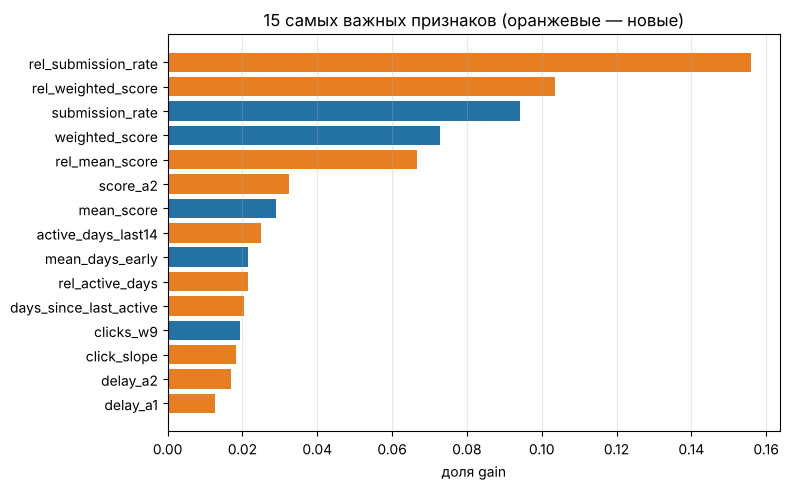

In [13]:
imp = pd.Series(lgbm_last.booster_.feature_importance("gain"), index=ALL_FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#e67e22" if c in ENRICHED else "#2471a3" for c in imp.index]
ax.barh(imp.index, imp.values, color=colors)
ax.set_title("15 самых важных признаков (оранжевые — новые)"); ax.set_xlabel("доля gain"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

## 9. Лучшая нейросеть: BiLSTM

На валидации сравнивались шесть архитектур, затем Optuna подбирала архитектуру, входы и параметры
обучения (60 попыток). Лучший вариант:

* **BiLSTM** — двунаправленная LSTM: читает 10 недель вперёд и назад, 128 нейронов в каждую сторону;
* вход-последовательность — те же 6 недельных показателей (добавление 20 типов материалов в
  последовательность не помогло: сеть быстрее переобучалась);
* второй вход — **все 85 табличных признаков** (а не только демография);
* dropout 0.38, AdamW (lr 0.00076), уменьшение шага при застое, обрезка градиента, ранняя остановка
  по ROC-AUC на валидации (терпение 10 эпох).

```
6 показателей × 10 недель ──► BiLSTM (2×128) ──┐
                                               ├─► Dropout ─► Dense(32) ─► Dense(1) ─► P(риск)
85 табличных признаков ────► Dense(32) ────────┘
```

In [14]:
class BiLSTMNet(nn.Module):
    def __init__(self, n_ch, n_st, hidden=128, static_hidden=32, dropout=0.381011454326618):
        super().__init__()
        self.rnn = nn.LSTM(n_ch, hidden, batch_first=True, bidirectional=True)
        self.static = nn.Sequential(nn.Linear(n_st, static_hidden), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden + static_hidden, 32), nn.ReLU(),
                                  nn.Dropout(dropout / 2), nn.Linear(32, 1))
    def forward(self, s, x):
        _, (h, _) = self.rnn(s)
        last = torch.cat([h[-2], h[-1]], dim=1)          # итог чтения вперёд и назад
        return self.head(torch.cat([last, self.static(x)], 1)).squeeze(1)

def train_bilstm(seed, lr=0.0007602566853341787, weight_decay=1.2024522365078874e-06, batch=256, max_epochs=80, patience=10):
    torch.manual_seed(seed); np.random.seed(seed); gen = torch.Generator().manual_seed(seed)
    sc = Scaler(seq[train_idx], X_all[train_idx])
    s_tr, x_tr = sc(seq[train_idx], X_all[train_idx]); s_va, x_va = sc(seq[val_idx], X_all[val_idx])
    y_tr = to_tensor(y[train_idx])
    net = BiLSTMNet(len(CHANNELS), X_all.shape[1])
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((len(y_tr) - y_tr.sum().item()) / y_tr.sum().item()))
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    best, best_state, stale = -1.0, None, 0
    for epoch in range(1, max_epochs + 1):
        net.train(); order = torch.randperm(len(y_tr), generator=gen)
        for i in range(0, len(order), batch):
            idx = order[i:i + batch]; opt.zero_grad()
            loss_fn(net(s_tr[idx], x_tr[idx]), y_tr[idx]).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        auc = roc_auc_score(y[val_idx], predict_net(net, s_va, x_va)); sched.step(auc)
        if auc > best + 1e-5: best, best_state, stale = auc, copy.deepcopy(net.state_dict()), 0
        else:
            stale += 1
            if stale >= patience: break
    net.load_state_dict(best_state)
    return net, sc, best, epoch

vs, ts = [], []
for s in range(N_SEEDS):
    net, sc, auc, ep = train_bilstm(seed=s)
    vs.append(predict_net(net, *sc(seq[val_idx], X_all[val_idx])))
    ts.append(predict_net(net, *sc(seq[test_idx], X_all[test_idx])))
    print(f"BiLSTM #{s + 1}: {ep} эпох, валидация ROC-AUC {auc:.4f}")
val_score["BiLSTM"], test_score["BiLSTM"] = np.mean(vs, axis=0), np.mean(ts, axis=0)

BiLSTM #1: 43 эпох, валидация ROC-AUC 0.8582


BiLSTM #2: 31 эпох, валидация ROC-AUC 0.8575


BiLSTM #3: 40 эпох, валидация ROC-AUC 0.8585


BiLSTM #4: 41 эпох, валидация ROC-AUC 0.8578


BiLSTM #5: 42 эпох, валидация ROC-AUC 0.8591


## 10. Ансамбль

Бустинг и нейросеть ошибаются по-разному: деревья хорошо работают с итоговыми числами, BiLSTM —
с порядком недель. Их взвешенное среднее обычно точнее каждой модели. Веса перебираем с шагом 0.1
и выбираем по ROC-AUC **на валидации**.

In [15]:
best_w, best_auc = None, -1
for a in np.arange(0, 1.01, 0.1):
    for b in np.arange(0, 1.01 - a, 0.1):
        c = 1 - a - b
        auc = roc_auc_score(y[val_idx], a * val_score["LightGBM"] + b * val_score["XGBoost"] + c * val_score["BiLSTM"])
        if auc > best_auc:
            best_auc, best_w = auc, (round(a, 1), round(b, 1), round(c, 1))
a, b, c = best_w
print(f"Веса: LightGBM {a}, XGBoost {b}, BiLSTM {c}; валидация ROC-AUC {best_auc:.4f}")
val_score["Ансамбль"] = a * val_score["LightGBM"] + b * val_score["XGBoost"] + c * val_score["BiLSTM"]
test_score["Ансамбль"] = a * test_score["LightGBM"] + b * test_score["XGBoost"] + c * test_score["BiLSTM"]

Веса: LightGBM 0.4, XGBoost 0.2, BiLSTM 0.4; валидация ROC-AUC 0.8617


## 11. Итог на тестовой выборке

Порог «в зоне риска / нет» для каждой модели выбирается так, чтобы F1 на **валидации** был
максимальным, — одинаковое правило для всех моделей.

,accuracy,precision,recall,f1,roc_auc,порог
Random Forest (базовые признаки),0.755,0.652,0.782,0.711,0.848,0.414
LSTM (первый ноутбук),0.760,0.655,0.803,0.721,0.856,0.403
LightGBM,0.771,0.679,0.771,0.722,0.861,0.365
XGBoost,0.758,0.653,0.799,0.719,0.860,0.334
BiLSTM,0.782,0.713,0.731,0.721,0.860,0.509
Ансамбль,0.763,0.659,0.800,0.723,0.862,0.375


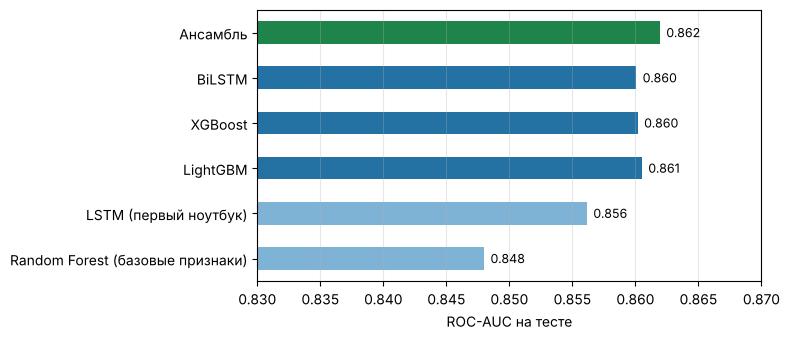

In [16]:
def f1_threshold(yv, sv):
    cands = np.unique(np.quantile(sv, np.linspace(0.02, 0.98, 97)))
    return float(cands[int(np.argmax([f1_score(yv, sv >= t) for t in cands]))])

final, preds = {}, {}
for name in val_score:
    thr = f1_threshold(y[val_idx], val_score[name])
    preds[name] = (test_score[name] >= thr).astype(int)
    final[name] = {**evaluate(y[test_idx], preds[name], test_score[name]), "порог": thr}
final = pd.DataFrame(final).T
display(final.style.format("{:.3f}").highlight_max(axis=0, subset=["accuracy", "f1", "roc_auc"], color="#d5f5e3"))

ax = final["roc_auc"].plot.barh(figsize=(8, 3.5), color=["#7fb3d5"] * 2 + ["#2471a3"] * 3 + ["#1e8449"])
ax.set_xlim(0.83, 0.87); ax.set_xlabel("ROC-AUC на тесте"); ax.grid(axis="x", alpha=.3)
for i, v in enumerate(final["roc_auc"]):
    ax.text(v + 0.0005, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 12. Значимость улучшения

Парный бутстрап по студентам (2000 повторов), как в первом ноутбуке: разница ROC-AUC ансамбля и
каждой другой модели, 95 %-й доверительный интервал и p-value.

In [17]:
def fast_auc(t, sc):
    n1 = t.sum(); n0 = len(t) - n1
    return (rankdata(sc)[t == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

y_te = y[test_idx]
codes, uniq = pd.factorize(groups.iloc[test_idx])
members = [np.flatnonzero(codes == g) for g in range(len(uniq))]
rng = np.random.default_rng(0)
boot = [np.concatenate([members[g] for g in rng.integers(0, len(members), len(members))]) for _ in range(2000)]
rows = []
for other in [k for k in test_score if k != "Ансамбль"]:
    a_, b_ = test_score["Ансамбль"], test_score[other]
    diffs = np.array([fast_auc(y_te[i], a_[i]) - fast_auc(y_te[i], b_[i]) for i in boot])
    p = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({"ансамбль против": other, "разница ROC-AUC": fast_auc(y_te, a_) - fast_auc(y_te, b_),
                 "95% ДИ": f"[{lo:+.3f}; {hi:+.3f}]", "p": p, "значимо": "да" if p < 0.05 else "нет"})
pd.DataFrame(rows).style.format({"разница ROC-AUC": "{:+.3f}", "p": "{:.3f}"})

,ансамбль против,разница ROC-AUC,95% ДИ,p,значимо
0,Random Forest (базовые признаки),+0.014,[+0.009; +0.019],0.000,да
1,LSTM (первый ноутбук),+0.006,[+0.003; +0.009],0.002,да
2,LightGBM,+0.001,[-0.000; +0.003],0.058,нет
3,XGBoost,+0.002,[+0.000; +0.003],0.031,да
4,BiLSTM,+0.002,[-0.000; +0.004],0.052,нет


## 13. Выводы

Итоговые выводы с проверкой на четырёх разных разбиениях — в файле `results\ЛУЧШАЯ_МОДЕЛЬ.md`.

* **Ансамбль** LightGBM + XGBoost + BiLSTM — самая точная модель; ROC-AUC на тесте выше, чем у прежней
  LSTM и Random Forest.
* Главный источник улучшения — **новые признаки** (типы материалов, перерывы, баллы по заданиям,
  активность относительно однокурсников), а не смена модели.
* Подобранные бустинг и BiLSTM на одних и тех же признаках дают почти одинаковую точность;
  объединение даёт небольшой дополнительный прирост.

### Приложение: как подбирались модели (только валидация, разбиение seed 42)

| Этап | Результат (ROC-AUC на валидации) |
|---|---|
| 6 архитектур с настройками по умолчанию | BiLSTM 0.856, LSTM 0.854, LSTM+attention 0.854, GRU 0.852, Transformer 0.851, CNN 0.848 |
| Optuna, 60 попыток по нейросетям | лучший — BiLSTM, 128 нейронов, 6 показателей + все табличные признаки: 0.859 |
| Optuna, 100 попыток LightGBM | 0.862 |
| Optuna, 60 попыток XGBoost | 0.862 |